# Flow Field

**Author:** Iman Mossavat · Fontys ICT

## What creates a flow field?

A flow field starts as ordinary random noise. After smoothing, each point in space gets a value, that value is turned into an angle, and a tiny step is taken in that direction. Repeating this for thousands of starting points creates the flowing lines you see below.

![Final flow field artwork](../assets/flow_field_preview.png)


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from math_vis import smooth_field, sample, make_cmap, finish, fig_to_img

# ---------- parameters ----------
SEED    = 11
BG      = '#14161f'
N_LINES = 4000      # lower for the explainer; raise for final print
STEPS   = 200
STEP    = 0.0035
SMOOTH  = 22
TWIST   = 0.9
DEMO_LINES = 150

# grid size for the underlying field
GW, GH = 256, 320
H = GH / GW

rng = np.random.default_rng(SEED)
palette = make_cmap(['#1d3557', '#3a6ea5', '#5bc0be', '#f4e3b1', '#f2a65a', '#d1495b'])

# build the smooth field and convert it to angles
field = smooth_field((GH, GW), SMOOTH, rng)
angle = field * np.pi * TWIST

# helper to sample the field at normalized (y, x) positions
def at(f, pts):
    return sample(f, pts[:, 1] * GW, pts[:, 0] * GW)

print(f'Field shape: {field.shape}  |  Canvas height: {H:.3f}')

Field shape: (320, 256)  |  Canvas height: 1.250


## CELL 2 · From randomness to spatial structure

Raw random numbers jump around from pixel to pixel. Passing them through a Gaussian convolution blends each pixel with its neighbors, so nearby locations end up with similar values. That spatial coherence is what turns noise into *structure*.

Run the next cell to compare a raw field with the smoothed version.

/var/folders/br/43qcm0hd6ds5_k6qgbcn6zhc0000gn/T/ipykernel_35023/1328857203.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


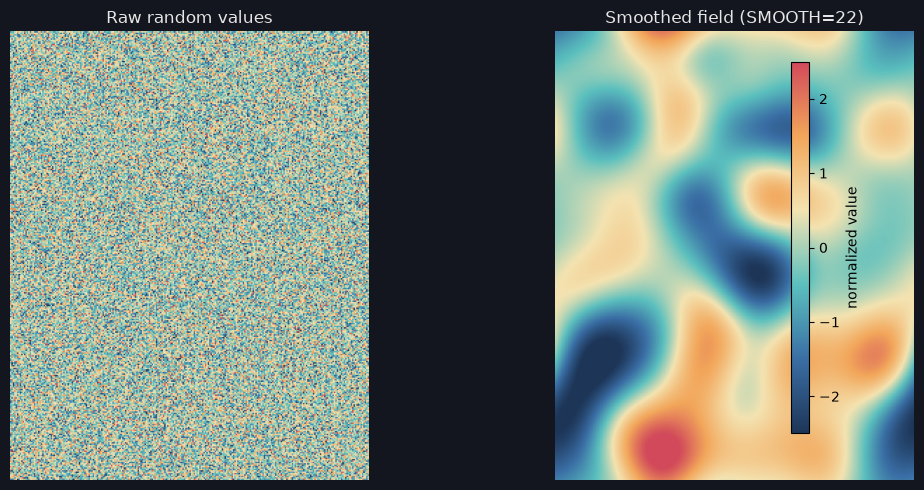

In [2]:
raw = rng.normal(size=(GH, GW))
raw = (raw - raw.mean()) / (raw.std() + 1e-12)   # normalize for comparison

fig, axs = plt.subplots(1, 2, figsize=(12, 5), facecolor=BG)
for ax, data, title in [
    (axs[0], raw, 'Raw random values'),
    (axs[1], field, f'Smoothed field (SMOOTH={SMOOTH})'),
]:
    ax.set_facecolor(BG)
    im = ax.imshow(data, origin='lower', cmap=palette, vmin=-2.5, vmax=2.5)
    ax.set_title(title, color='#e6e6e6')
    ax.axis('off')
fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02, label='normalized value')
plt.tight_layout(); plt.show()

> **Question:** What would change if you increased `SMOOTH`? Would the lines in the final image look tighter, looser, or about the same? Make a prediction, then try it.

## CELL 3 · From values to directions

Each value in the smooth field is mapped to an angle:

$$
\\theta(x, y) = \\text{TWIST} \\cdot \\pi \\cdot f(x, y)
$$

The direction at that point is the unit vector $(\\cos\\theta, \\sin\\theta)$. The left panel shows the scalar field; the right panel shows the same field as angles, with a few direction arrows overlaid.

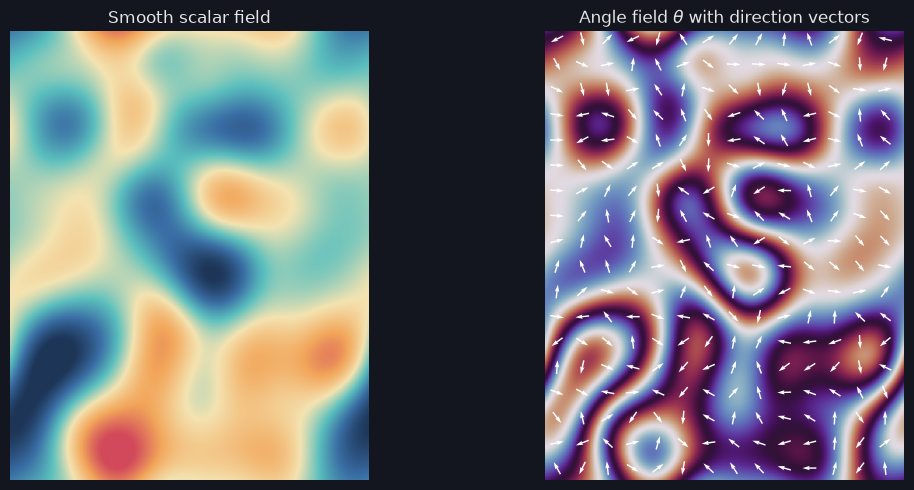

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), facecolor=BG)

ax = axs[0]
ax.set_facecolor(BG)
ax.imshow(field, origin='lower', extent=(0, 1, 0, H), cmap=palette, vmin=-2.5, vmax=2.5)
ax.set_title('Smooth scalar field', color='#e6e6e6')
ax.axis('off')

ax = axs[1]
ax.set_facecolor(BG)
ax.imshow(np.mod(angle, 2 * np.pi), origin='lower', extent=(0, 1, 0, H),
          cmap='twilight', vmin=0, vmax=2 * np.pi)
# overlay a sparse quiver plot
r_, c_ = np.arange(8, GH, 18), np.arange(8, GW, 18)
X, Y = np.meshgrid((c_ + 0.5) / GW, (r_ + 0.5) / GW)
a_ = angle[np.ix_(r_, c_)]
ax.quiver(X, Y, np.cos(a_), np.sin(a_), color='white', pivot='mid', scale=26, width=0.004)
ax.set_title(r'Angle field $\theta$ with direction vectors', color='#e6e6e6')
ax.axis('off')

plt.tight_layout(); plt.show()

> **Question:** Neighboring pixels have similar angles because of the smoothing step. Why do paths that start near each other tend to curve together?

## CELL 4 · Following the field

A path is built one small step at a time. If $\\mathbf{x}_t$ is the current position and $\\mathbf{v}(\\mathbf{x}_t)$ is the local direction, the next position is:

$$
\\mathbf{x}_{t+1} = \\mathbf{x}_t + h \\mathbf{v}(\\mathbf{x}_t)
$$

Here $h$ is `STEP`. This is a simple Euler-style integration step: we evaluate the direction where we are, move a little, and repeat.

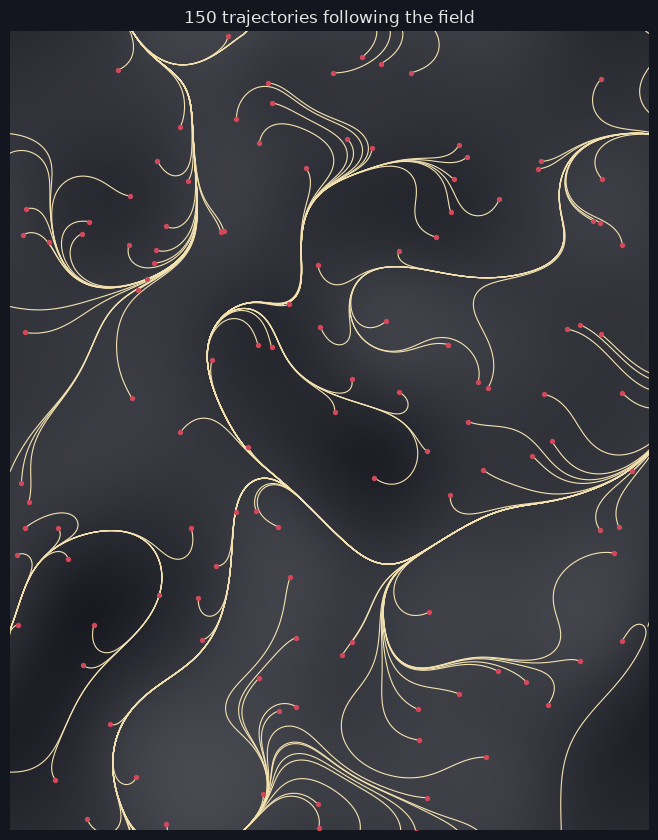

In [4]:
# create a jittered grid of starting points
side = int(np.sqrt(N_LINES))
gx, gy = np.meshgrid(
    np.linspace(-0.05, 1.05, side),
    np.linspace(-0.05, 1.30, N_LINES // side)
)
pts = np.column_stack([gx.ravel(), gy.ravel()])
pts = pts + rng.normal(0, 0.006, pts.shape)
n = len(pts)
seeds = pts.copy()

# integrate every path
paths = np.empty((n, STEPS, 2))
paths[:, 0] = pts
for i in range(1, STEPS):
    a = at(angle, pts)
    pts = pts + STEP * np.column_stack([np.cos(a), np.sin(a)])
    paths[:, i] = pts

# show a sample of trajectories
demo = rng.choice(n, DEMO_LINES, replace=False)
fig, ax = plt.subplots(figsize=(7, 8.5), facecolor=BG)
ax.set_facecolor(BG)
ax.set_xlim(0, 1); ax.set_ylim(0, H); ax.set_aspect('equal')
ax.axis('off')
ax.imshow(field, origin='lower', extent=(0, 1, 0, H), cmap='Greys_r',
          vmin=-4, vmax=4, alpha=0.25)
ax.add_collection(LineCollection(paths[demo], colors='#f4e3b1', linewidths=0.8))
ax.scatter(seeds[demo, 0], seeds[demo, 1], s=8, color='#d1495b', zorder=3)
ax.set_title(f'{DEMO_LINES} trajectories following the field', color='#e6e6e6')
plt.tight_layout(); plt.show()

> **Question:** What might happen if `STEP` became much larger — say ten times larger? Would the paths stay smooth? Try to predict before changing the value.

## CELL 5 · Change one thing at a time

The next two cells produce the full visual experiment. Before you run them, look at what each parameter controls:

| Parameter | What it changes | Mainly math or rendering? |
|-----------|----------------|---------------------------|
| `SMOOTH`  | Width of the Gaussian blur that creates spatial structure | **math** |
| `TWIST`   | How far values are stretched before becoming angles | **math** |
| `STEP`    | Length of each integration step | **math** |
| `N_LINES` | How many trajectories are drawn | rendering |
| `STEPS`   | How long each trajectory is | rendering |
| `DEMO_LINES` | How many trajectories appear in the explainer panels | rendering |

Try changing **only one** parameter at a time, then re-run the cells from the parameter cell onward. Predict the effect first, then compare.

In [5]:
# Edit these values, then re-run the cells from here down.
# The defaults reproduce the artwork shown at the top of the notebook.
SEED    = 11
N_LINES = 4000
STEPS   = 200
STEP    = 0.0035
SMOOTH  = 22
TWIST   = 0.9
DEMO_LINES = 150

# Recompute the field and paths with the new parameters
rng = np.random.default_rng(SEED)
field = smooth_field((GH, GW), SMOOTH, rng)
angle = field * np.pi * TWIST

side = int(np.sqrt(N_LINES))
gx, gy = np.meshgrid(
    np.linspace(-0.05, 1.05, side),
    np.linspace(-0.05, 1.30, N_LINES // side)
)
pts = np.column_stack([gx.ravel(), gy.ravel()])
pts = pts + rng.normal(0, 0.006, pts.shape)
n = len(pts)
seeds = pts.copy()

paths = np.empty((n, STEPS, 2))
paths[:, 0] = pts
for i in range(1, STEPS):
    a = at(angle, pts)
    pts = pts + STEP * np.column_stack([np.cos(a), np.sin(a)])
    paths[:, i] = pts

start_value = at(field, paths[:, 0])
t = 0.5 + 0.28 * start_value + rng.normal(0, 0.05, n)
colors = palette(np.clip(t, 0, 1))
colors[:, 3] = rng.uniform(0.15, 0.5, n)
widths = rng.uniform(0.3, 1.4, n)
print('Parameters updated and paths recomputed.')

Parameters updated and paths recomputed.


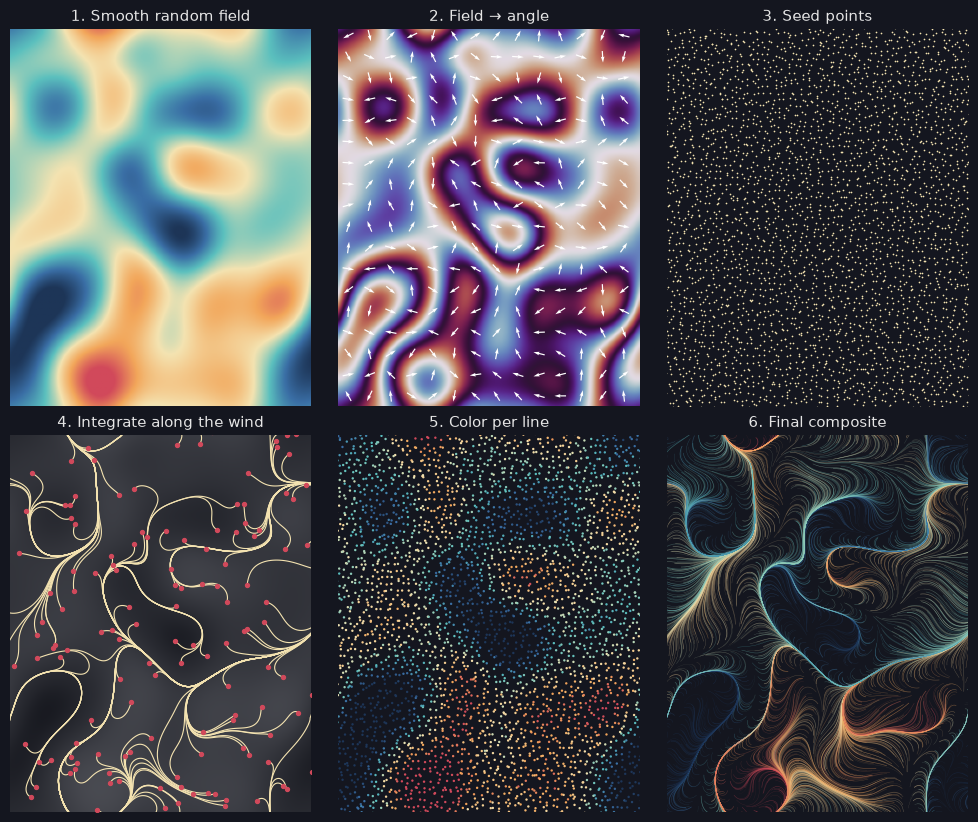

In [6]:
# ---------- SIX-PANEL VISUAL EXPLAINER ----------
def canvas(ax, title):
    ax.set_facecolor(BG)
    ax.set_xlim(0, 1); ax.set_ylim(0, H); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(title, color='#e6e6e6', fontsize=11)

demo = rng.choice(n, DEMO_LINES, replace=False)
fig, axs = plt.subplots(2, 3, figsize=(10, 8.3), facecolor=BG)

ax = axs[0,0]; canvas(ax, '1. Smooth random field')
ax.imshow(field, origin='lower', extent=(0,1,0,H), cmap=palette, vmin=-2.5, vmax=2.5)

ax = axs[0,1]; canvas(ax, '2. Field → angle')
ax.imshow(np.mod(angle, 2*np.pi), origin='lower', extent=(0,1,0,H), cmap='twilight', vmin=0, vmax=2*np.pi)
r_, c_ = np.arange(8, GH, 18), np.arange(8, GW, 18)
X, Y = np.meshgrid((c_+0.5)/GW, (r_+0.5)/GW)
a_ = angle[np.ix_(r_, c_)]
ax.quiver(X, Y, np.cos(a_), np.sin(a_), color='white', pivot='mid', scale=26, width=0.004)

ax = axs[0,2]; canvas(ax, '3. Seed points')
ax.scatter(seeds[:,0], seeds[:,1], s=1.5, color='#f4e3b1', lw=0)

ax = axs[1,0]; canvas(ax, '4. Integrate along the wind')
ax.imshow(field, origin='lower', extent=(0,1,0,H), cmap='Greys_r', vmin=-4, vmax=4, alpha=0.25)
ax.add_collection(LineCollection(paths[demo], colors='#f4e3b1', linewidths=0.8))
ax.scatter(seeds[demo,0], seeds[demo,1], s=8, color='#d1495b', zorder=3)

ax = axs[1,1]; canvas(ax, '5. Color per line')
ax.scatter(seeds[:,0], seeds[:,1], s=3, c=np.clip(t,0,1), cmap=palette, vmin=0, vmax=1, lw=0)

ax = axs[1,2]; canvas(ax, '6. Final composite')
ax.add_collection(LineCollection(paths, colors=colors, linewidths=widths*0.4, capstyle='round'))

plt.tight_layout(); plt.show()

## CELL 6 · What did we learn?

- **Smoothing** turns independent random values into a coherent spatial pattern. Without it, the field would be too chaotic to produce flowing lines.
- **Angles** are just scalar values scaled by `TWIST` and wrapped onto the unit circle. The same field can produce very different visuals by changing the twist.
- **Integration** traces trajectories by repeatedly adding a small direction step. The step size controls how faithfully the path follows the field.
- **Rendering choices** such as the number of lines, their length, their color, and their transparency turn the mathematical trajectories into an image.

**Open questions:**
1. What happens if the direction is computed from a *combination* of two independently smoothed fields?
2. Could you make the step size `h` depend on position or on the local curvature?

**Further experiment:** Try using a different color palette or making `TWIST` negative. How does reversing the direction field change the overall composition?

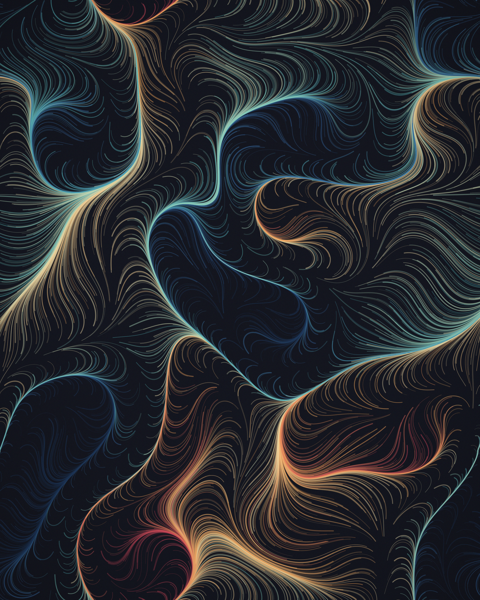

In [7]:
# ---------- FINAL RENDER ----------
# High-resolution file for the gallery + a small preview embedded in the notebook
from IPython.display import display
from PIL import Image

fig = plt.figure(figsize=(8, 10), dpi=300)
ax = fig.add_axes([0, 0, 1, 1])
fig.patch.set_facecolor(BG)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.25); ax.axis('off')
ax.add_collection(LineCollection(paths, colors=colors, linewidths=widths, capstyle='round'))
img = finish(fig_to_img(fig), name='flow_field.png', grain=3, vignette=0.25, display=False)

# Embed a lightweight preview so the notebook stays small
preview = Image.fromarray(img).resize((480, 600))
display(preview)